In [1]:
import keras

from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical

In [2]:
import matplotlib.pyplot as plt

In [3]:
# import the data
from keras.datasets import mnist

# read the data
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 16s 1us/step


In [4]:
X_train.shape

(60000, 28, 28)

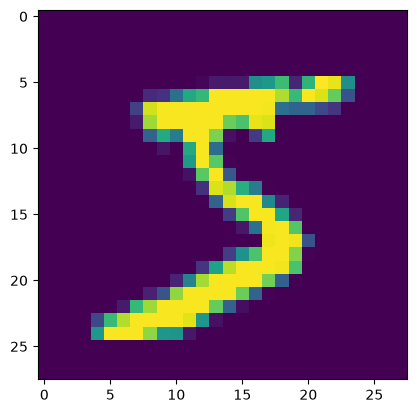

In [5]:
plt.imshow(X_train[0])

In [6]:
# flatten images into one-dimensional vector

num_pixels = X_train.shape[1] * X_train.shape[2] # find size of one-dimensional vector

X_train = X_train.reshape(X_train.shape[0], num_pixels).astype('float32') # flatten training images
X_test = X_test.reshape(X_test.shape[0], num_pixels).astype('float32') # flatten test images

In [7]:
# normalize inputs from 0-255 to 0-1
X_train = X_train / 255
X_test = X_test / 255

In [8]:
# one hot encode outputs
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

num_classes = y_test.shape[1]
print(num_classes)

10


# Build a Neural Network

In [9]:
# define classification model
def classification_model():
    # create model
    model = Sequential()
    model.add(Dense(num_pixels, activation='relu', input_shape=(num_pixels,)))
    model.add(Dense(100, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    
    
    # compile model
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Train and Test the Network

In [10]:
# build the model
model = classification_model()

# fit the model
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, verbose=2)

# evaluate the model
scores = model.evaluate(X_test, y_test, verbose=0)

c:\Users\user\OneDrive\Desktop\Deep Learning\neural-computational-lab\.venv\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9447 - loss: 0.1834 - val_accuracy: 0.9667 - val_loss: 0.1028
Epoch 2/10
1875/1875 - 15s - 8ms/step - accuracy: 0.9771 - loss: 0.0749 - val_accuracy: 0.9716 - val_loss: 0.0856
Epoch 3/10
1875/1875 - 16s - 8ms/step - accuracy: 0.9845 - loss: 0.0491 - val_accuracy: 0.9767 - val_loss: 0.0830
Epoch 4/10
1875/1875 - 15s - 8ms/step - accuracy: 0.9887 - loss: 0.0361 - val_accuracy: 0.9790 - val_loss: 0.0768
Epoch 5/10
1875/1875 - 22s - 12ms/step - accuracy: 0.9908 - loss: 0.0289 - val_accuracy: 0.9793 - val_loss: 0.0862
Epoch 6/10
1875/1875 - 19s - 10ms/step - accuracy: 0.9922 - loss: 0.0240 - val_accuracy: 0.9782 - val_loss: 0.0988
Epoch 7/10
1875/1875 - 16s - 8ms/step - accuracy: 0.9931 - loss: 0.0207 - val_accuracy: 0.9780 - val_loss: 0.1011
Epoch 8/10
1875/1875 - 16s - 8ms/step - accuracy: 0.9938 - loss: 0.0190 - val_accuracy: 0.9786 - val_loss: 0.1045
Epoch 9/10
1875/1875 - 15s - 8ms/step - accuracy: 0.9945 - loss: 0.0183 - val_accurac

In [11]:
print('Accuracy: {}% \n Error: {}'.format(scores[1], 1 - scores[1]))        

Accuracy: 0.9793999791145325% 
 Error: 0.02060002088546753


In [12]:
model.save('classification_model.h5')

In [13]:
from keras.models import load_model

In [14]:
pretrained_model = load_model('classification_model.h5')